# Bengaluru Real Estate Market Intelligence: Exploratory Data Analysis
**Empirical Valuation Patterns, Micro-Market Disparities, and Data Quality Governance**

---

### Project Scope & Context
- **Dataset**: Bengaluru House Price Dataset (12,640 verified residential listings across urban Bengaluru, Karnataka, India).
- **Attribution**: Created by Amitabha Chakraborty under **CC0: Public Domain** licensing.
- **Data Nature**: Online real estate portal **asking / listing prices** in **Lakhs of Indian Rupees (₹ Lakhs)**, where 1 Lakh = ₹100,000.
- **Analytical Governance**: All analysis is based on `data/processed/bengaluru_clean.csv`, generated by `src.bengaluru_data_prep` following transparent deduplication, safe unit parsing, and explicit review-flagging.


In [1]:
import json
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Ensure project root is in sys.path when running from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import config
from src.bengaluru_data_prep import clean_bengaluru_data

# Display formatting
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Load cleaned dataset
clean_path = config.BENGALURU_CLEAN_DATA_PATH
df = pd.read_csv(clean_path)
print(f"Loaded clean Bengaluru dataset: {df.shape[0]:,} records, {df.shape[1]} features.")


Loaded clean Bengaluru dataset: 12,640 records, 21 features.


## 1. Cleaned Dataset Architecture & Verification

The cleaned dataset contains 12,640 residential listings with parsed numeric features, domain indicators, and diagnostic review flags.


In [2]:
display_cols = [
    'area_type', 'location_clean', 'total_sqft_clean', 'bhk',
    'bath', 'balcony', 'price', 'price_per_sqft', 'is_ready_to_move', 'is_in_named_society'
]
df[display_cols].head(5)


,area_type,location_clean,total_sqft_clean,bhk,bath,balcony,price,price_per_sqft,is_ready_to_move,is_in_named_society
0,Super built-up Area,Electronic City Phase II,"1,056.00",2.00,2.00,1.00,39.07,"3,699.81",0,1
1,Plot Area,Chikka Tirupathi,"2,600.00",4.00,5.00,3.00,120.00,"4,615.38",1,1
2,Built-up Area,Uttarahalli,"1,440.00",3.00,2.00,3.00,62.00,"4,305.56",1,0
3,Super built-up Area,Lingadheeranahalli,"1,521.00",3.00,3.00,1.00,95.00,"6,245.89",1,1
4,Super built-up Area,Kothanur,"1,200.00",2.00,2.00,1.00,51.00,"4,250.00",1,0


## 2. Target Variable Analysis: Asking Price (₹ Lakhs & ₹ Crores)

Housing prices in Bengaluru exhibit pronounced positive right-skewness (**skewness = 7.95**), with 50% of homes priced between **₹50.0 Lakhs** and **₹120.0 Lakhs**, while luxury estates extend up to **₹3,600.0 Lakhs (₹36 Crore)**.


In [3]:
p = df['price']
log_p = np.log1p(p)

price_stats = {
    'Metric': ['Count', 'Minimum', '25th Percentile (Q1)', 'Median', 'Mean', '75th Percentile (Q3)', 'Maximum', 'Skewness (Raw)', 'Skewness (log1p)'],
    'Value (₹ Lakhs)': [
        f"{len(p):,}",
        f"₹{p.min():.1f}L (₹{p.min()*100000:,.0f})",
        f"₹{p.quantile(0.25):.1f}L",
        f"₹{p.median():.1f}L (₹{p.median()*100000:,.0f})",
        f"₹{p.mean():.1f}L (₹{p.mean()*100000:,.0f})",
        f"₹{p.quantile(0.75):.1f}L",
        f"₹{p.max():.1f}L (₹{p.max()*100000:,.0f})",
        f"{p.skew():.2f}",
        f"{log_p.skew():.2f}"
    ]
}
pd.DataFrame(price_stats)


,Metric,Value (₹ Lakhs)
0,Count,"12,640"
1,Minimum,"₹8.0L (₹800,000)"
2,25th Percentile (Q1),₹50.0L
3,Median,"₹72.0L (₹7,200,000)"
4,Mean,"₹114.1L (₹11,413,236)"
5,75th Percentile (Q3),₹120.0L
6,Maximum,"₹3600.0L (₹360,000,000)"
7,Skewness (Raw),7.95
8,Skewness (log1p),0.86


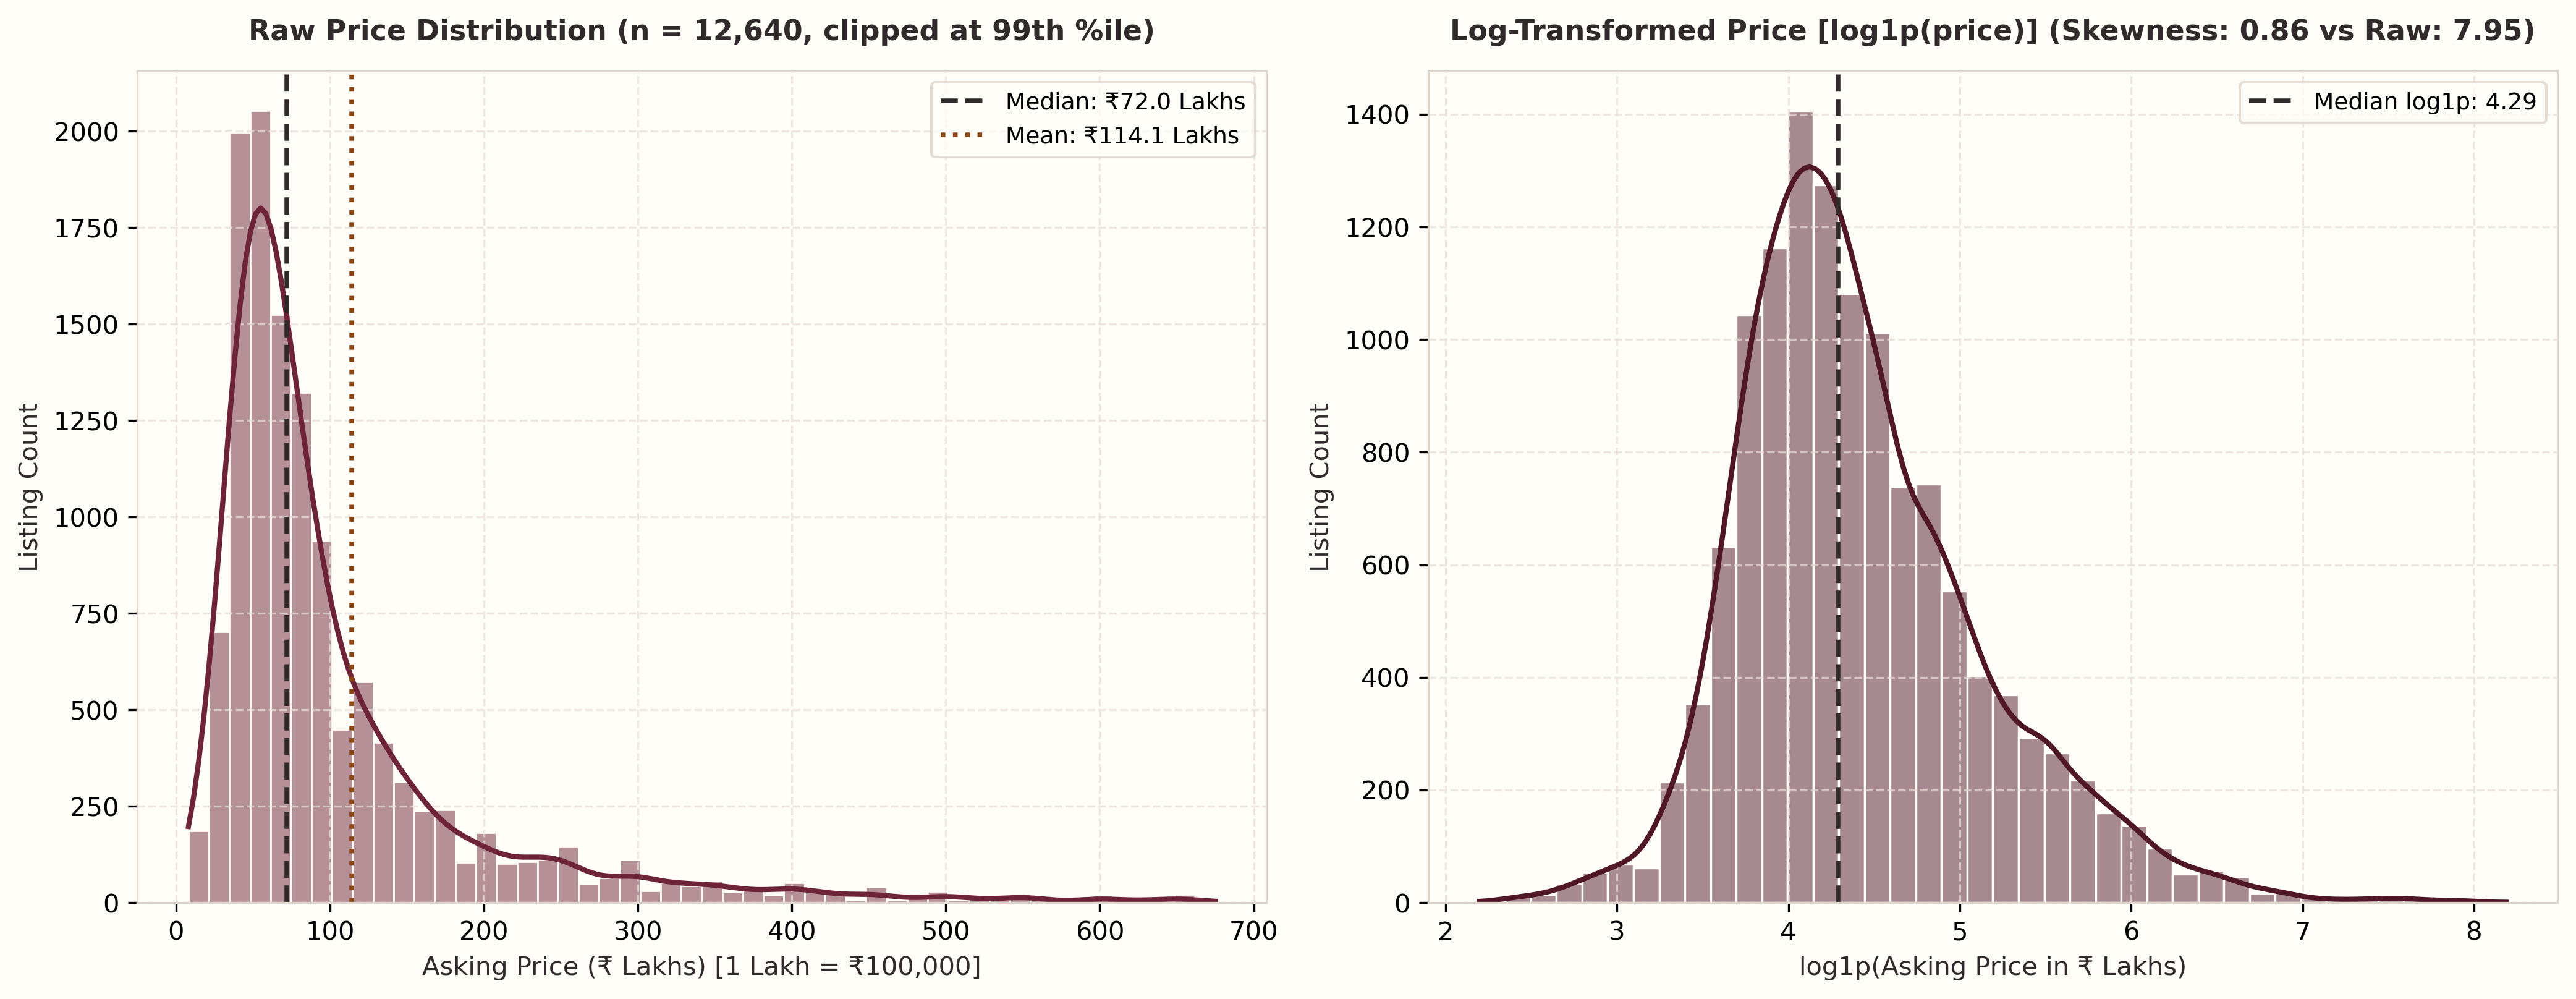

In [4]:
from IPython.display import Image, display
fig1_path = config.PROJECT_ROOT / "reports" / "figures" / "bengaluru" / "01_price_distribution_and_log.png"
display(Image(filename=str(fig1_path)))


## 3. Physical Specifications: Price vs. Bedroom Count (BHK) and Total Living Area

- **Bedroom Progression**: Median prices rise systematically from 1 BHK (₹34.8L) to 2 BHK (₹54.0L), 3 BHK (₹90.0L), and 4 BHK (₹205.0L).
- **Living Area Correlation**: Total square footage demonstrates a strong Spearman rank correlation ($\\rho = 0.75$) with asking price.


In [5]:
bhk_table = (
    df[(df['bhk'] >= 1) & (df['bhk'] <= 6)]
    .groupby('bhk')['price']
    .agg(Listing_Count='count', Median_Price_Lakhs='median', Mean_Price_Lakhs='mean', Std_Dev='std')
    .reset_index()
)
bhk_table['BHK_Tier'] = bhk_table['bhk'].astype(int).astype(str) + ' BHK'
bhk_table = bhk_table[['BHK_Tier', 'Listing_Count', 'Median_Price_Lakhs', 'Mean_Price_Lakhs', 'Std_Dev']]
bhk_table


,BHK_Tier,Listing_Count,Median_Price_Lakhs,Mean_Price_Lakhs,Std_Dev
0,1 BHK,636,34.78,45.31,55.72
1,2 BHK,5244,54.00,59.92,30.75
2,3 BHK,4651,90.00,112.24,88.33
3,4 BHK,1389,205.00,273.20,264.33
4,5 BHK,333,180.00,291.13,339.02
5,6 BHK,183,175.00,248.25,275.28


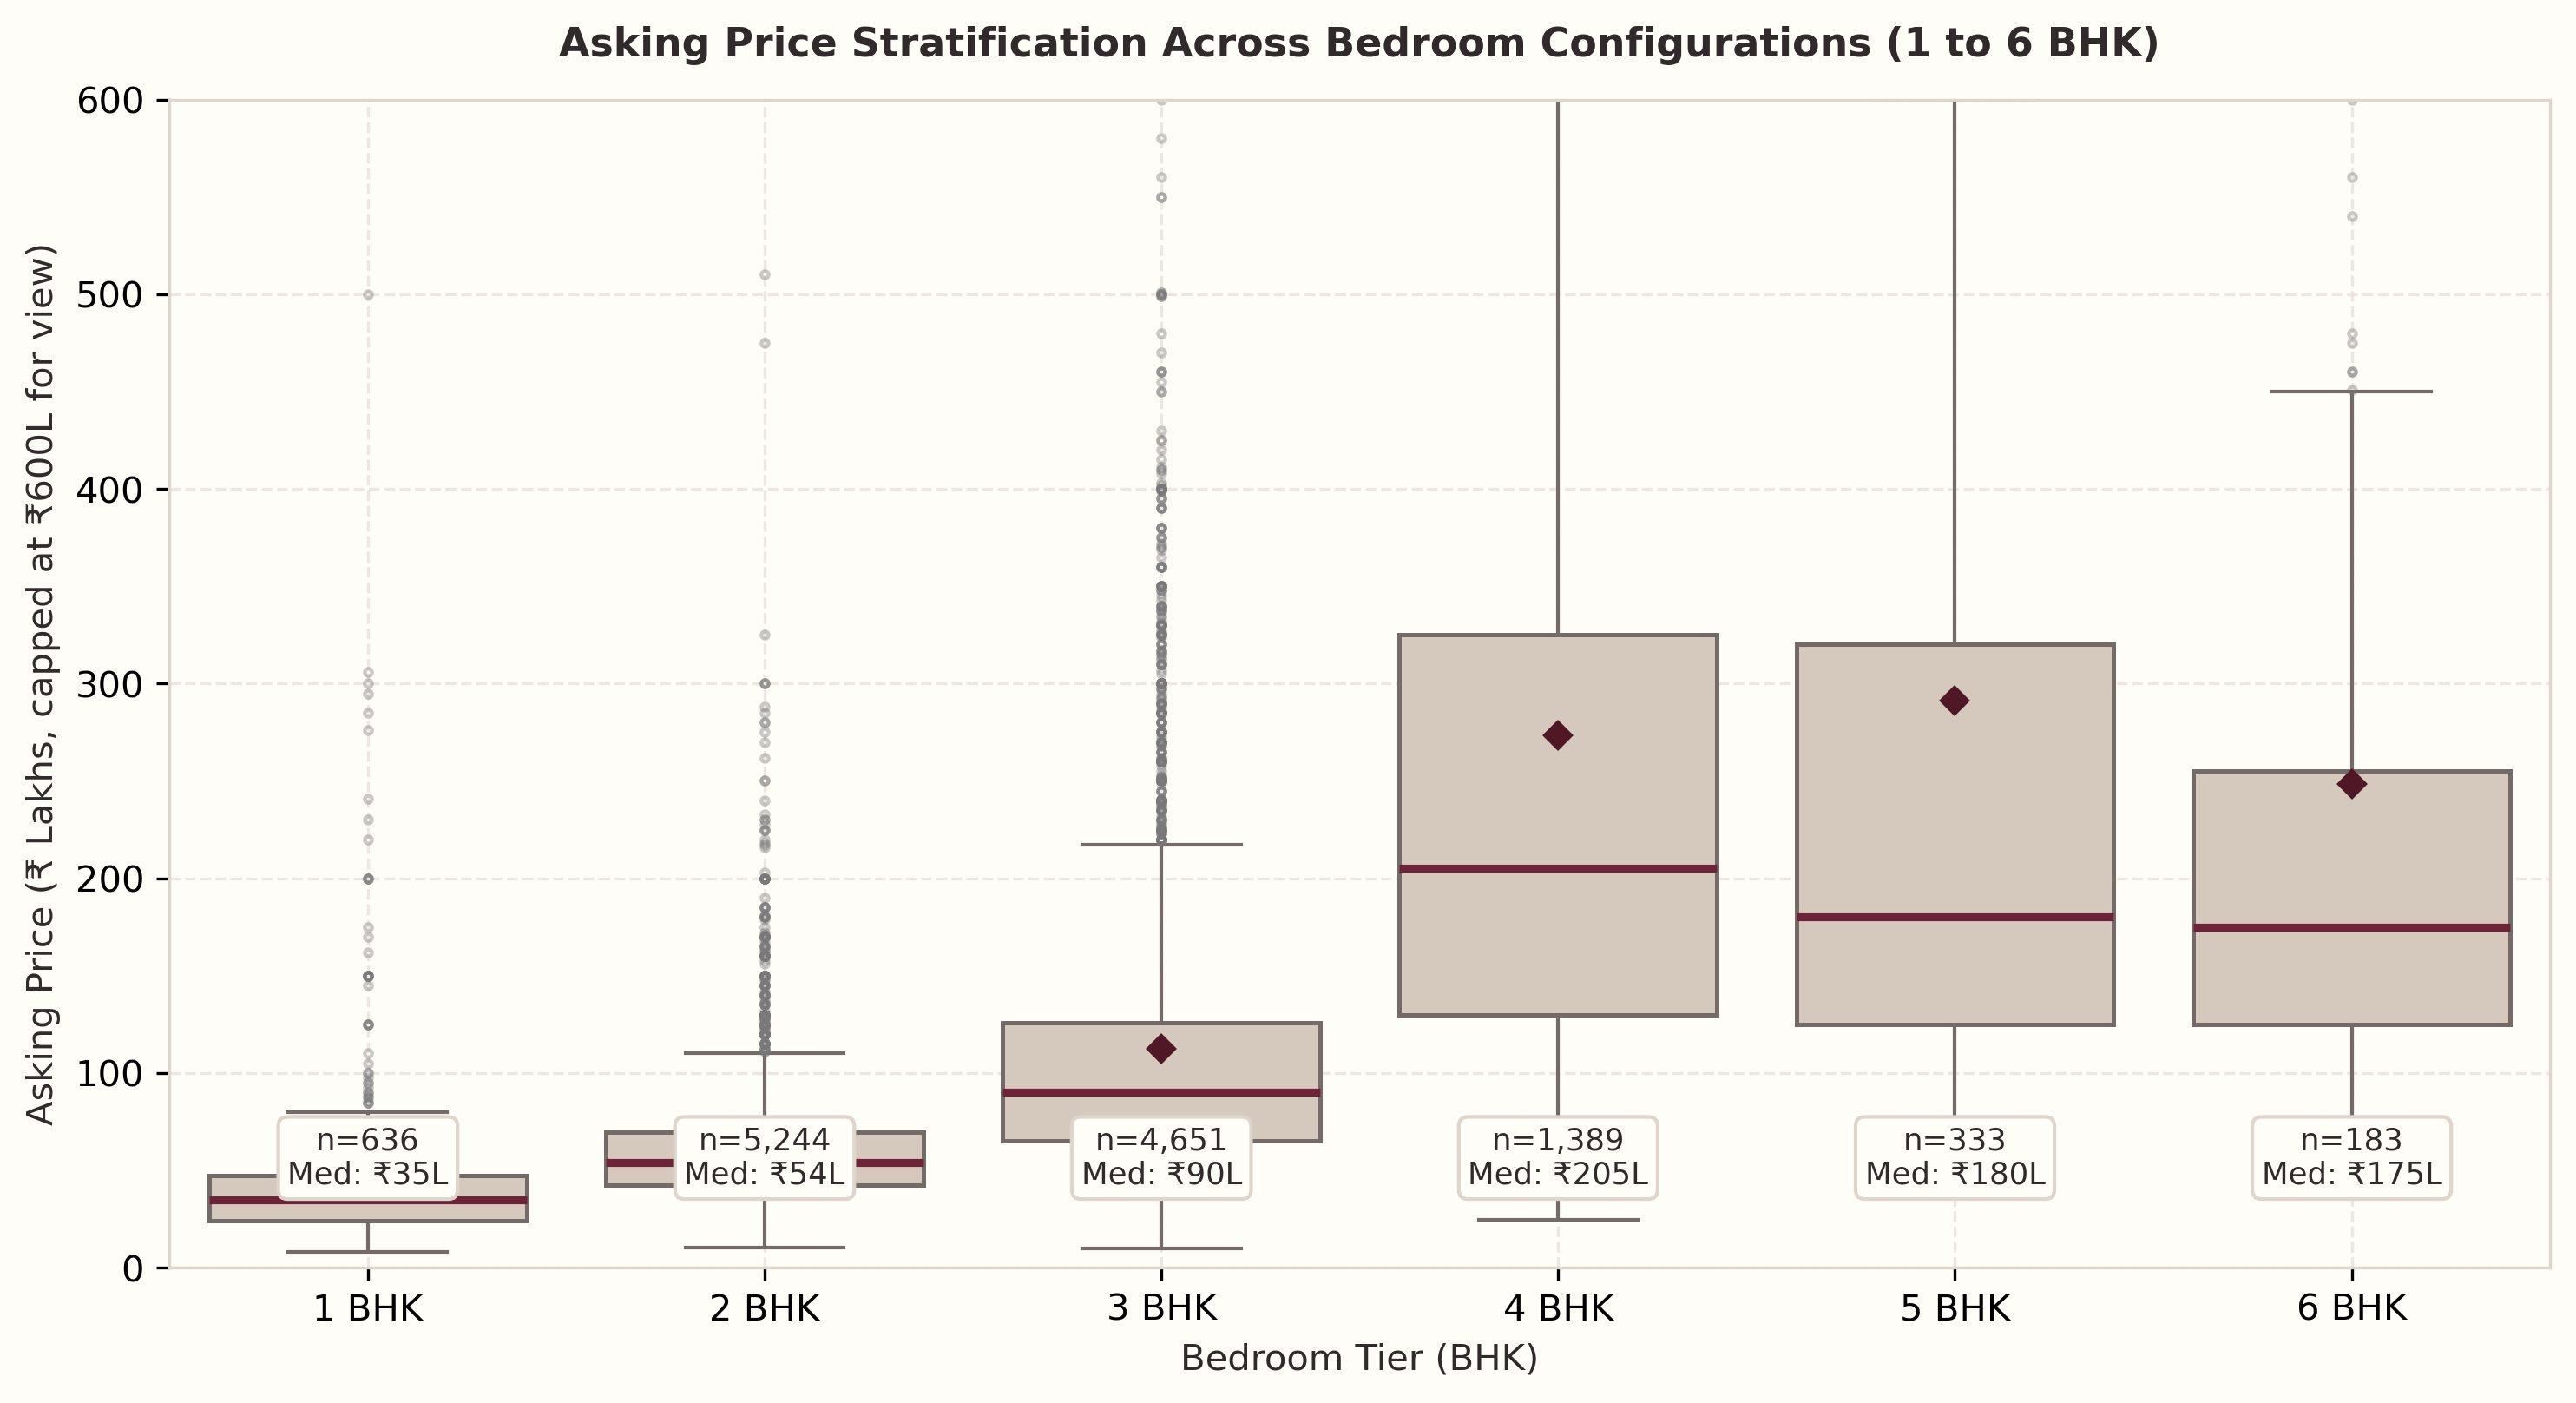

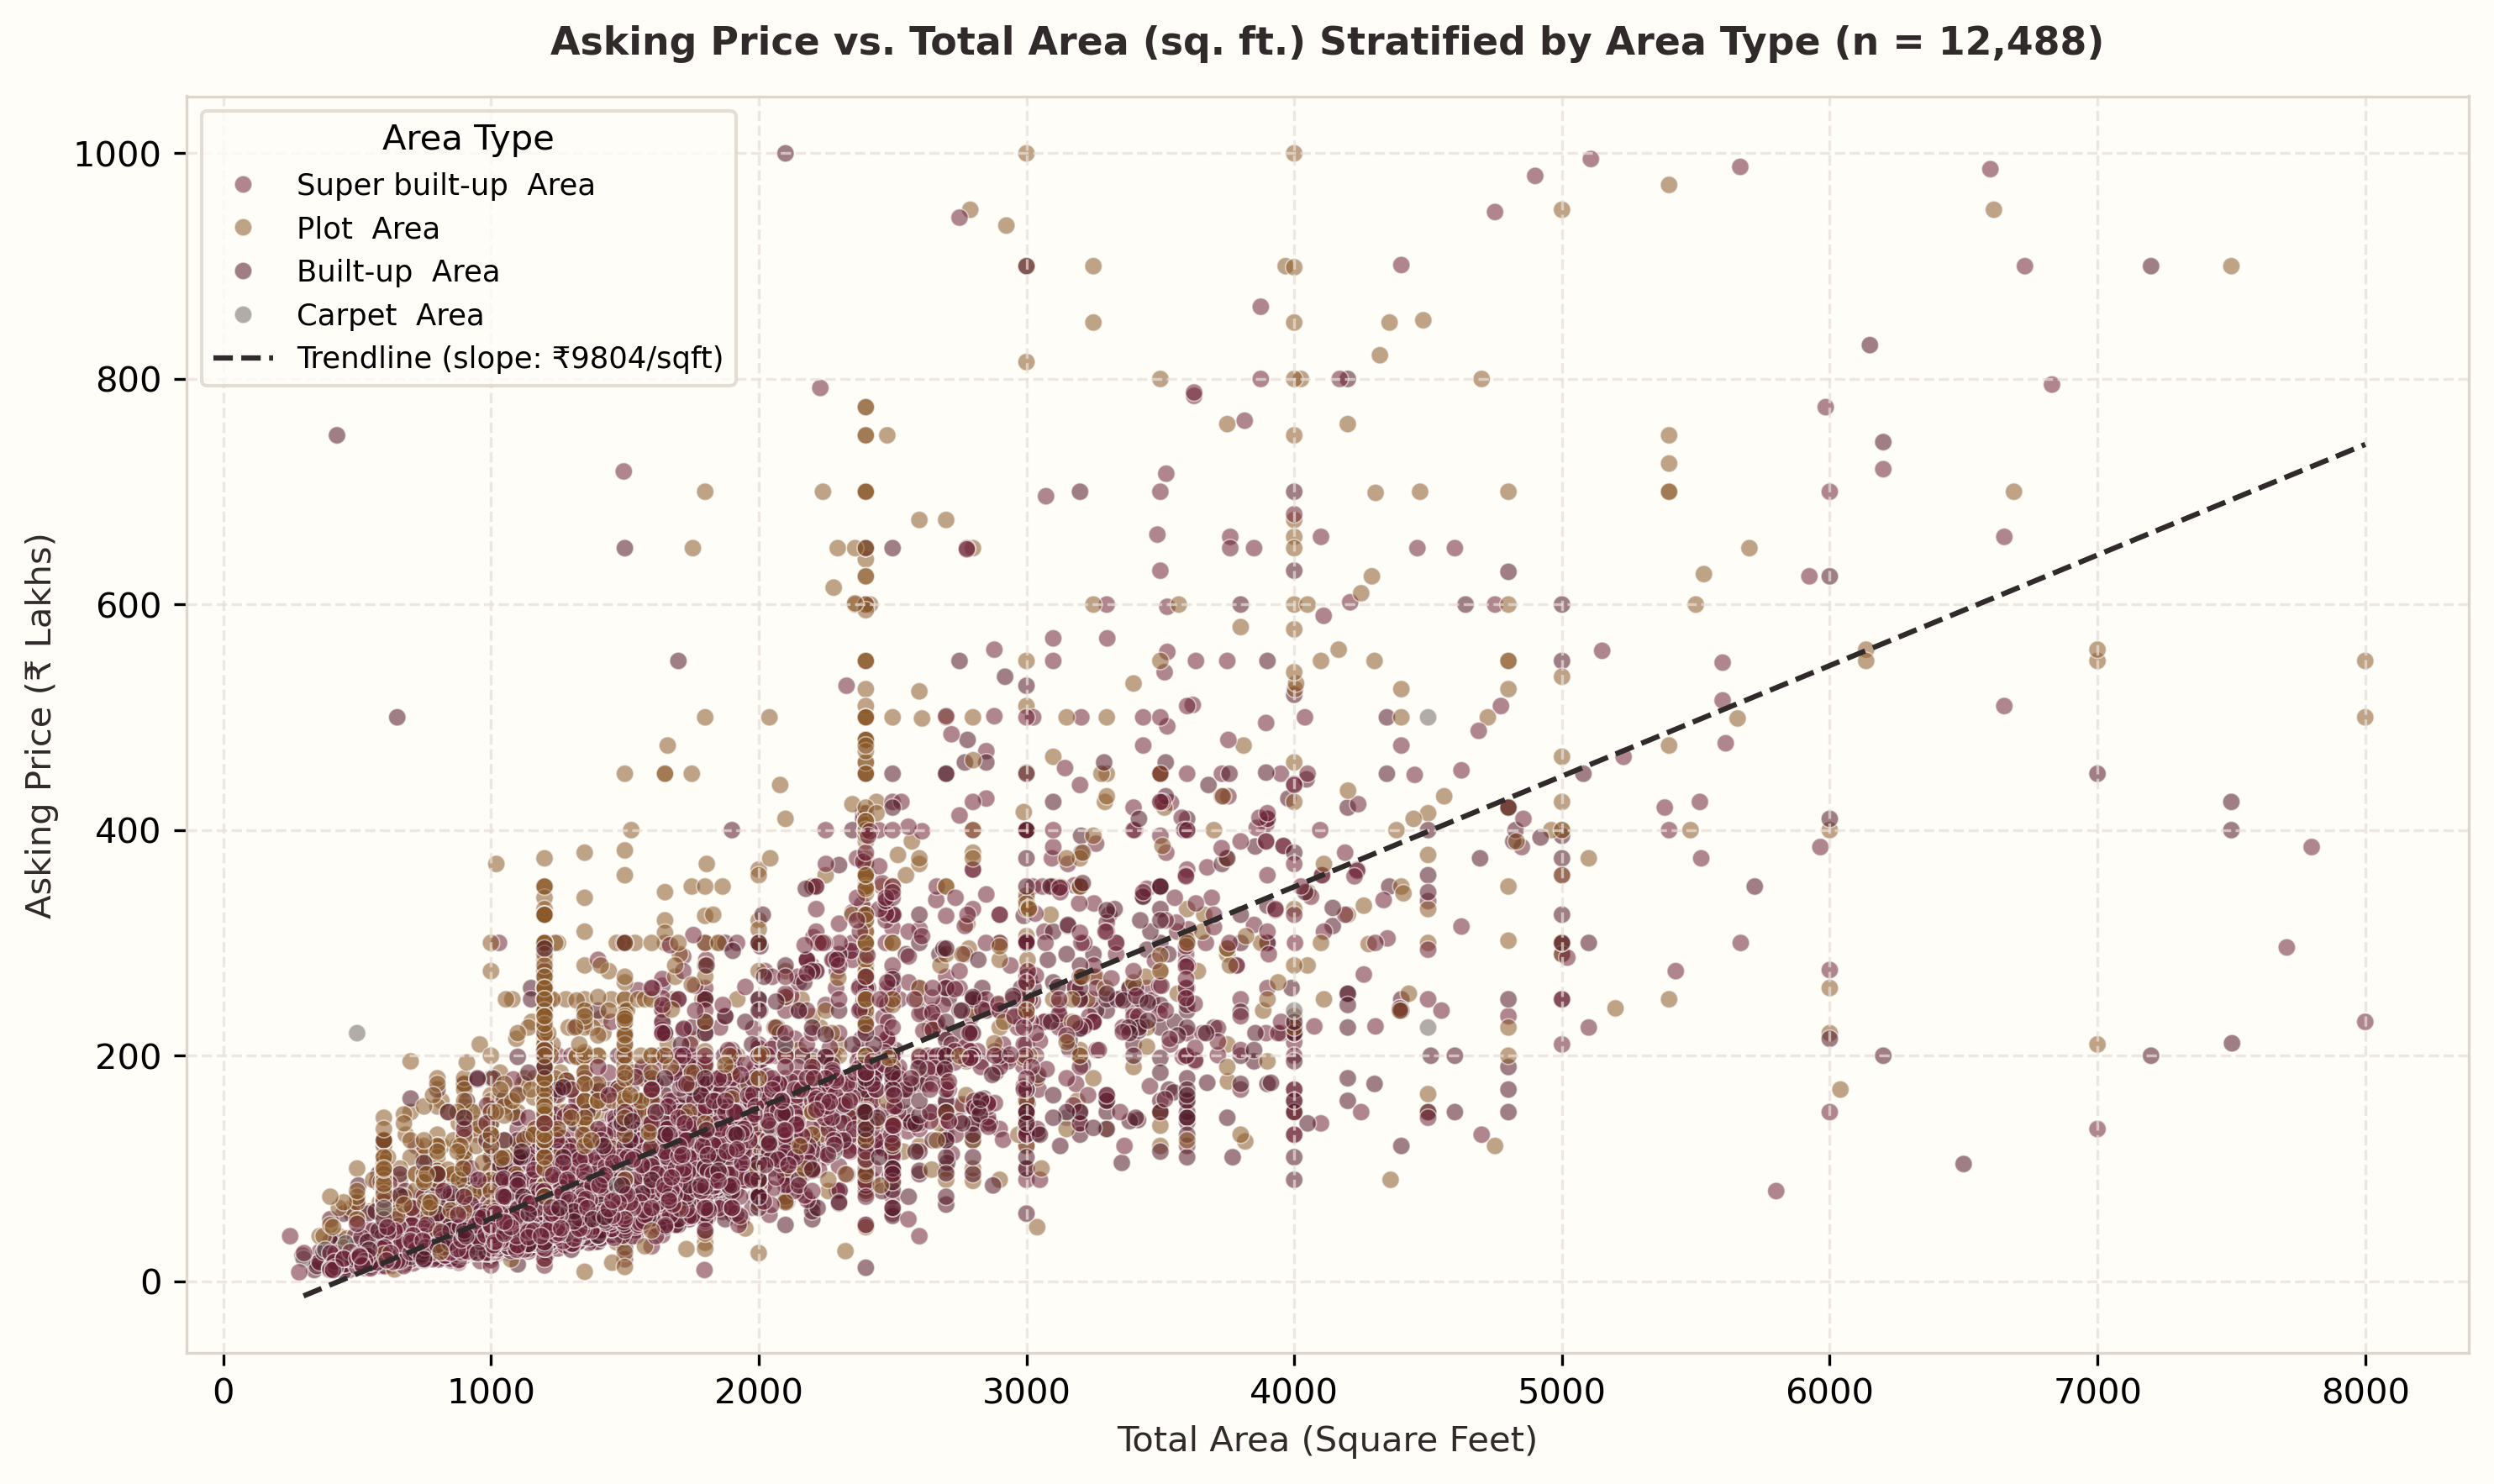

In [6]:
fig2_path = config.PROJECT_ROOT / "reports" / "figures" / "bengaluru" / "02_price_by_bhk.png"
fig3_path = config.PROJECT_ROOT / "reports" / "figures" / "bengaluru" / "03_price_vs_total_sqft.png"
display(Image(filename=str(fig2_path)))
display(Image(filename=str(fig3_path)))


## 4. Development Typology: Impact of Area Type on Pricing

- **Apartment Market (`Super built-up Area`)**: Dominates with 65.8% of listings (median: ₹65.3L).
- **Independent Land (`Plot Area`)**: Commands a substantial premium (median: **₹145.0L**, mean: **₹216.0L**), reflecting the scarcity of freehold land in central/established Bengaluru.


,area_type,Listings,Median_Lakhs,Mean_Lakhs,Market_Share
2,Plot Area,1862,145.00,216.00,14.7%
0,Built-up Area,2381,70.00,104.72,18.8%
1,Carpet Area,85,70.00,90.08,0.7%
3,Super built-up Area,8312,65.26,94.25,65.8%


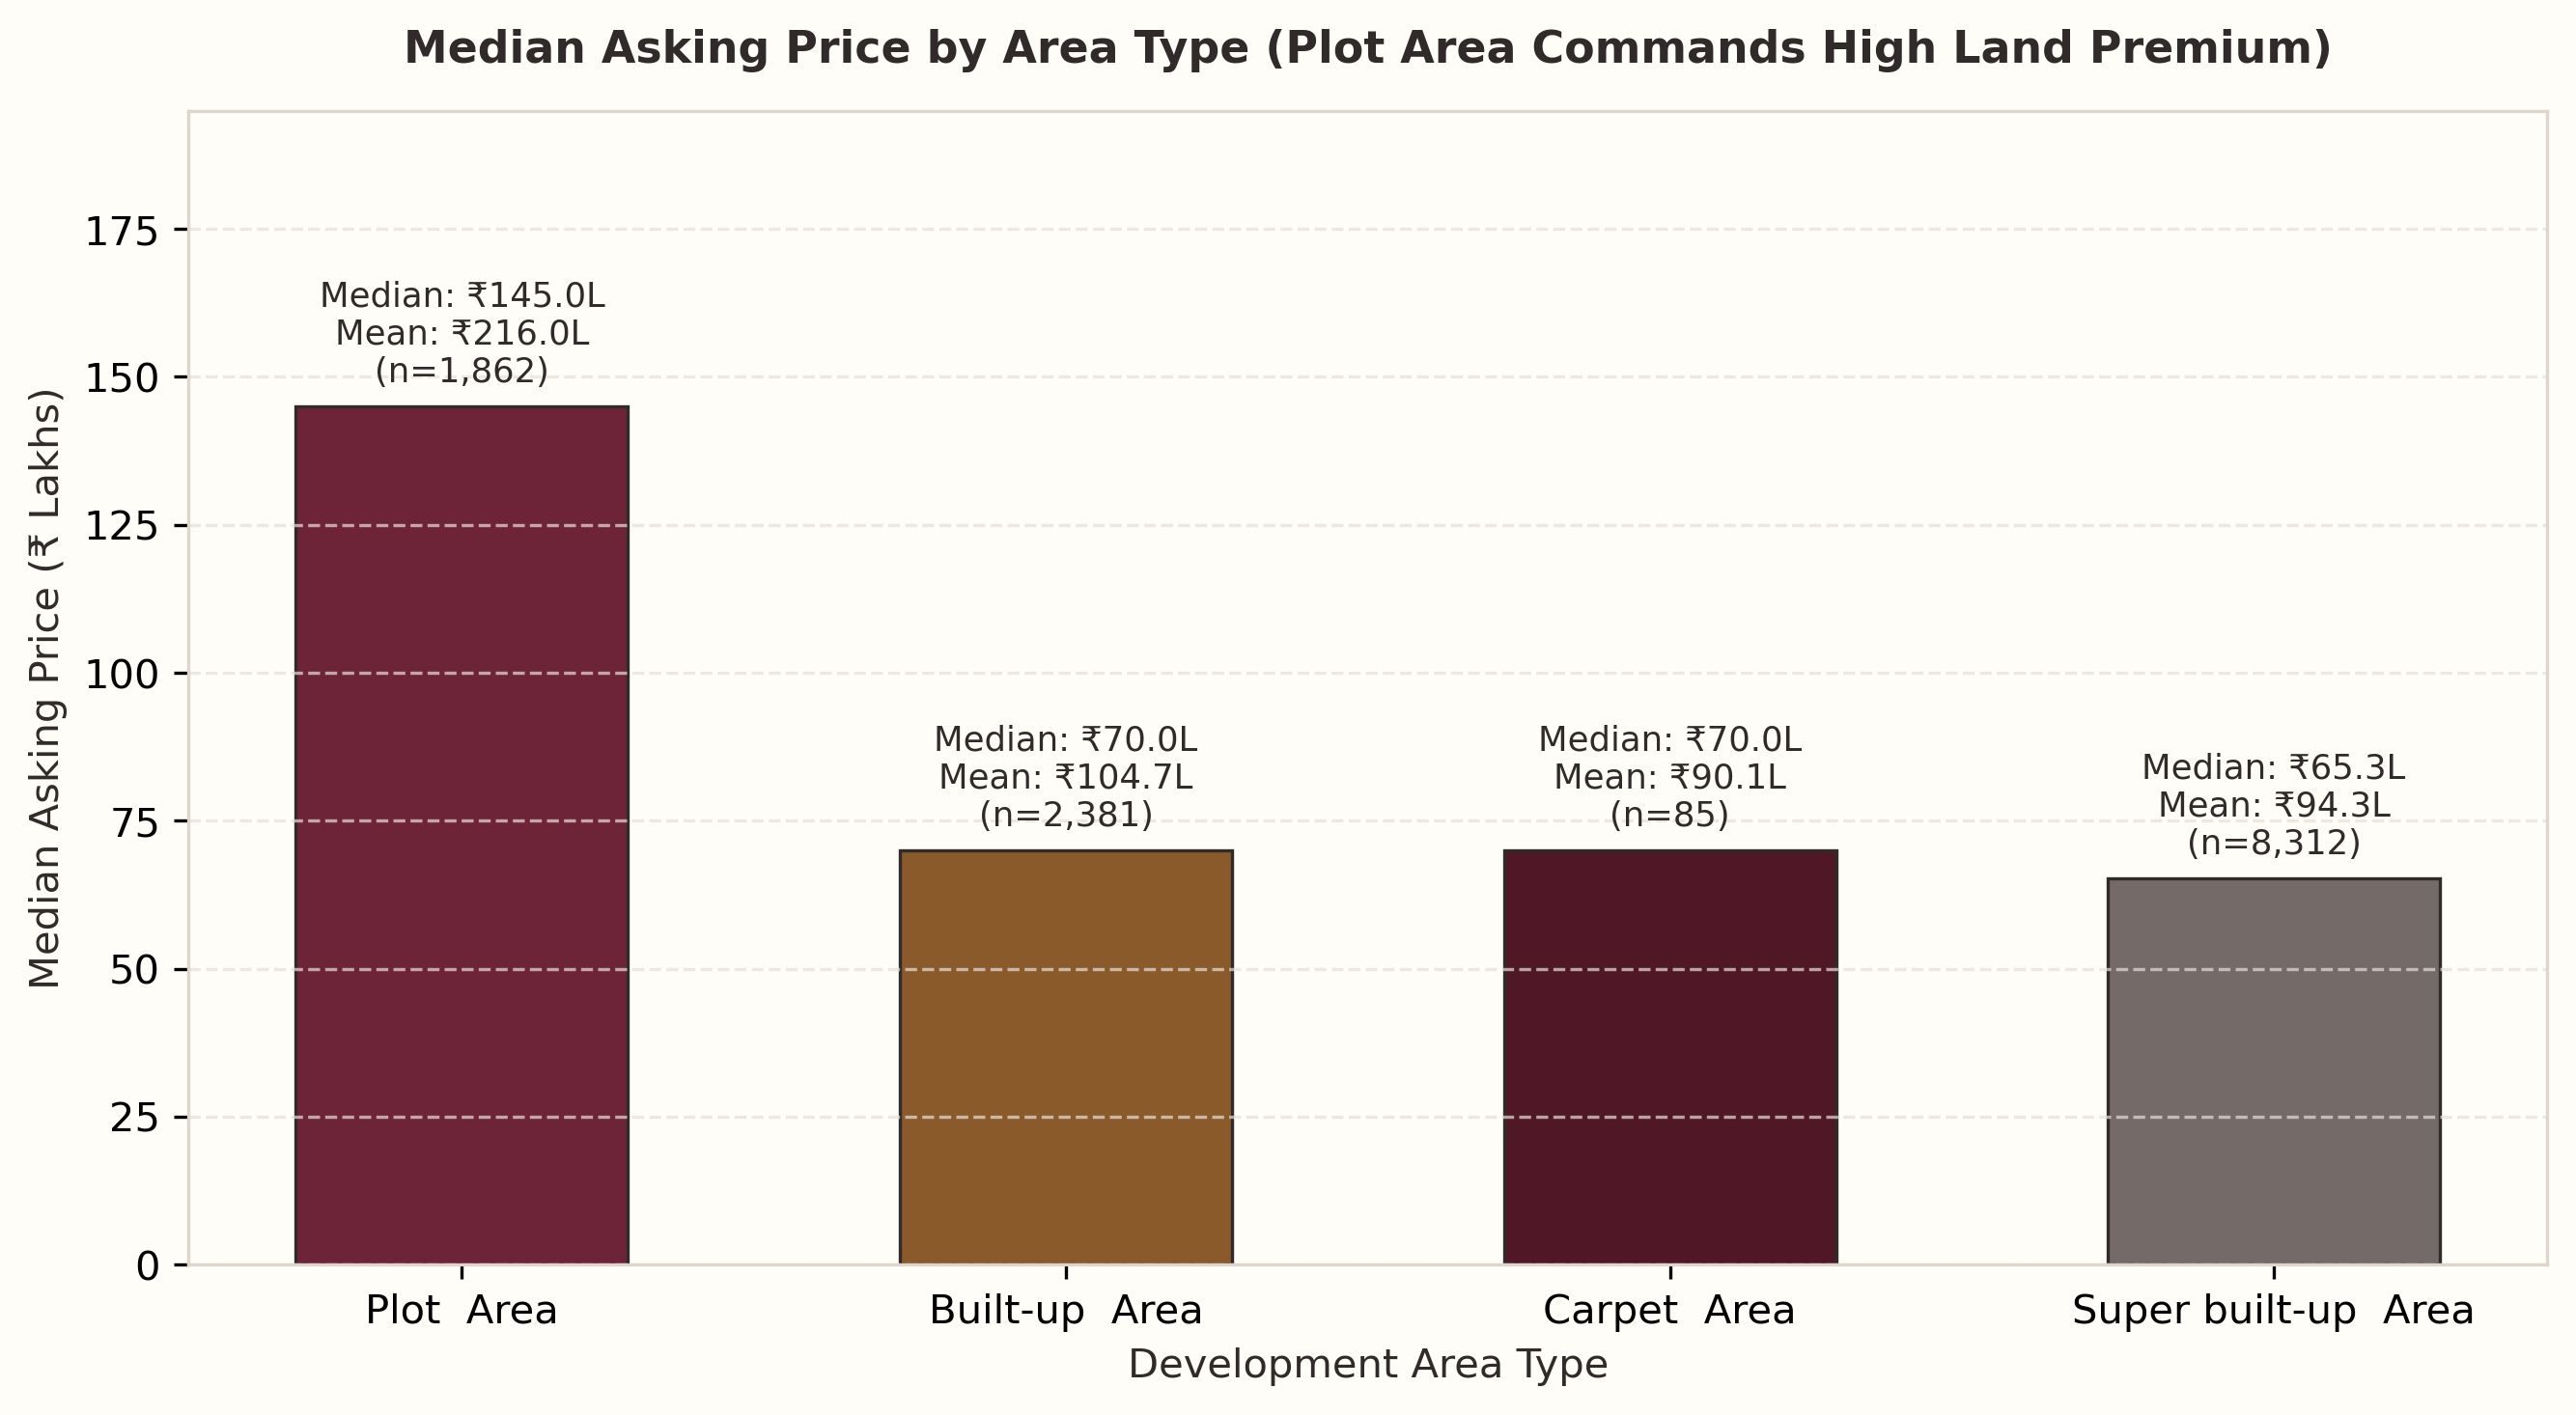

In [7]:
area_table = (
    df.groupby('area_type')['price']
    .agg(Listings='count', Median_Lakhs='median', Mean_Lakhs='mean')
    .reset_index()
    .sort_values('Median_Lakhs', ascending=False)
)
area_table['Market_Share'] = (area_table['Listings'] / len(df) * 100).map(lambda x: f'{x:.1f}%')
display(area_table)

fig4_path = config.PROJECT_ROOT / "reports" / "figures" / "bengaluru" / "04_price_by_area_type.png"
display(Image(filename=str(fig4_path)))


## 5. Locality-Level Price Disparities: Micro-Market Valuation Tiers

To avoid statistical distortion from micro-markets with very few listings, ranking is restricted to localities with **at least 30 verified listings** ($n \ge 30$).

Top premium micro-markets:
1. **Malleshwaram**: Median ₹261.0L ($n = 54$)
2. **Rajaji Nagar**: Median ₹251.0L ($n = 105$)
3. **Frazer Town**: Median ₹210.0L ($n = 36$)
4. **Indira Nagar**: Median ₹191.0L ($n = 43$)
5. **Hebbal Kempapura**: Median ₹170.0L ($n = 33$)


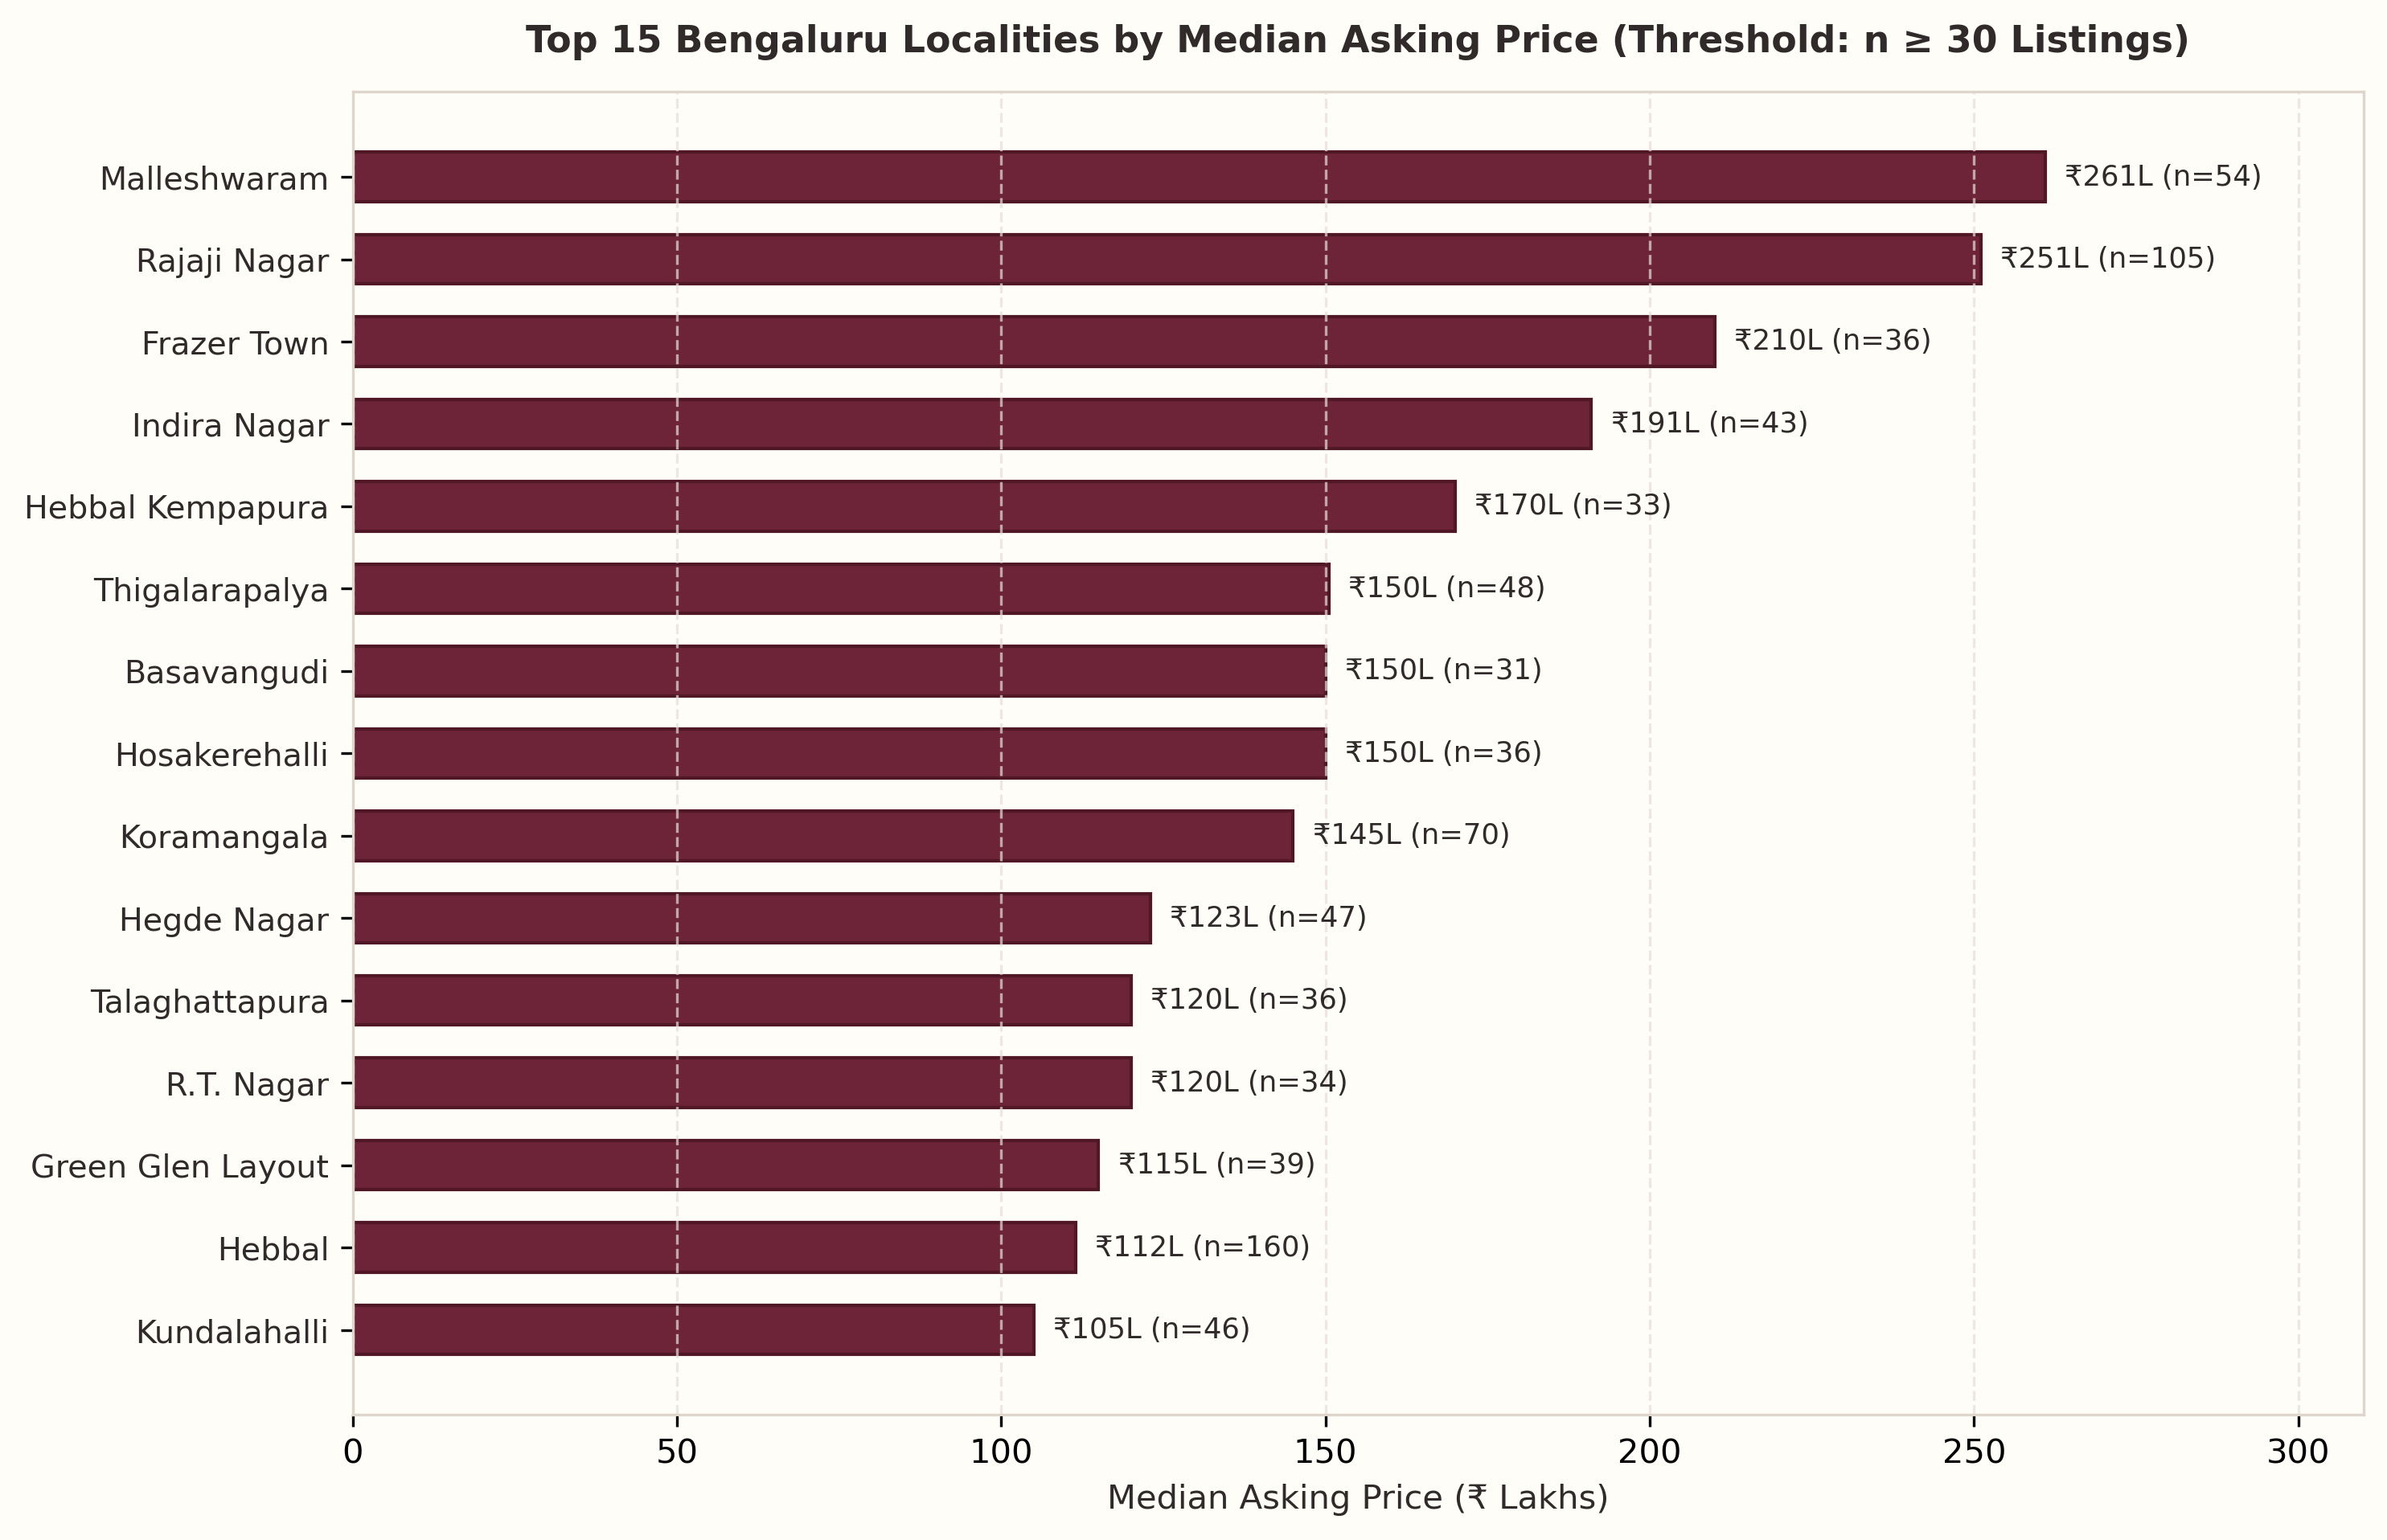

In [8]:
fig5_path = config.PROJECT_ROOT / "reports" / "figures" / "bengaluru" / "05_top15_localities_median_price.png"
display(Image(filename=str(fig5_path)))


## 6. Rank Correlation Hierarchy Among Numerical Attributes

Spearman rank correlation evaluates monotonic relationships without assuming linear bivariate normality:
- **Price per Sq. Ft.** ($\\rho = 0.81$): Strongest driver of total valuation.
- **Total Area** ($\\rho = 0.75$): Scale remains the dominant physical determinant.
- **Bathrooms** ($\\rho = 0.72$) and **Bedrooms** ($\\rho = 0.69$): Highly correlated with scale and luxury tier.
- **Balconies** ($\\rho = 0.20$): Weak positive correlation.
- **Named Society** ($\\rho = -0.06$): Slight negative raw correlation due to large volume of affordable suburban township apartments.


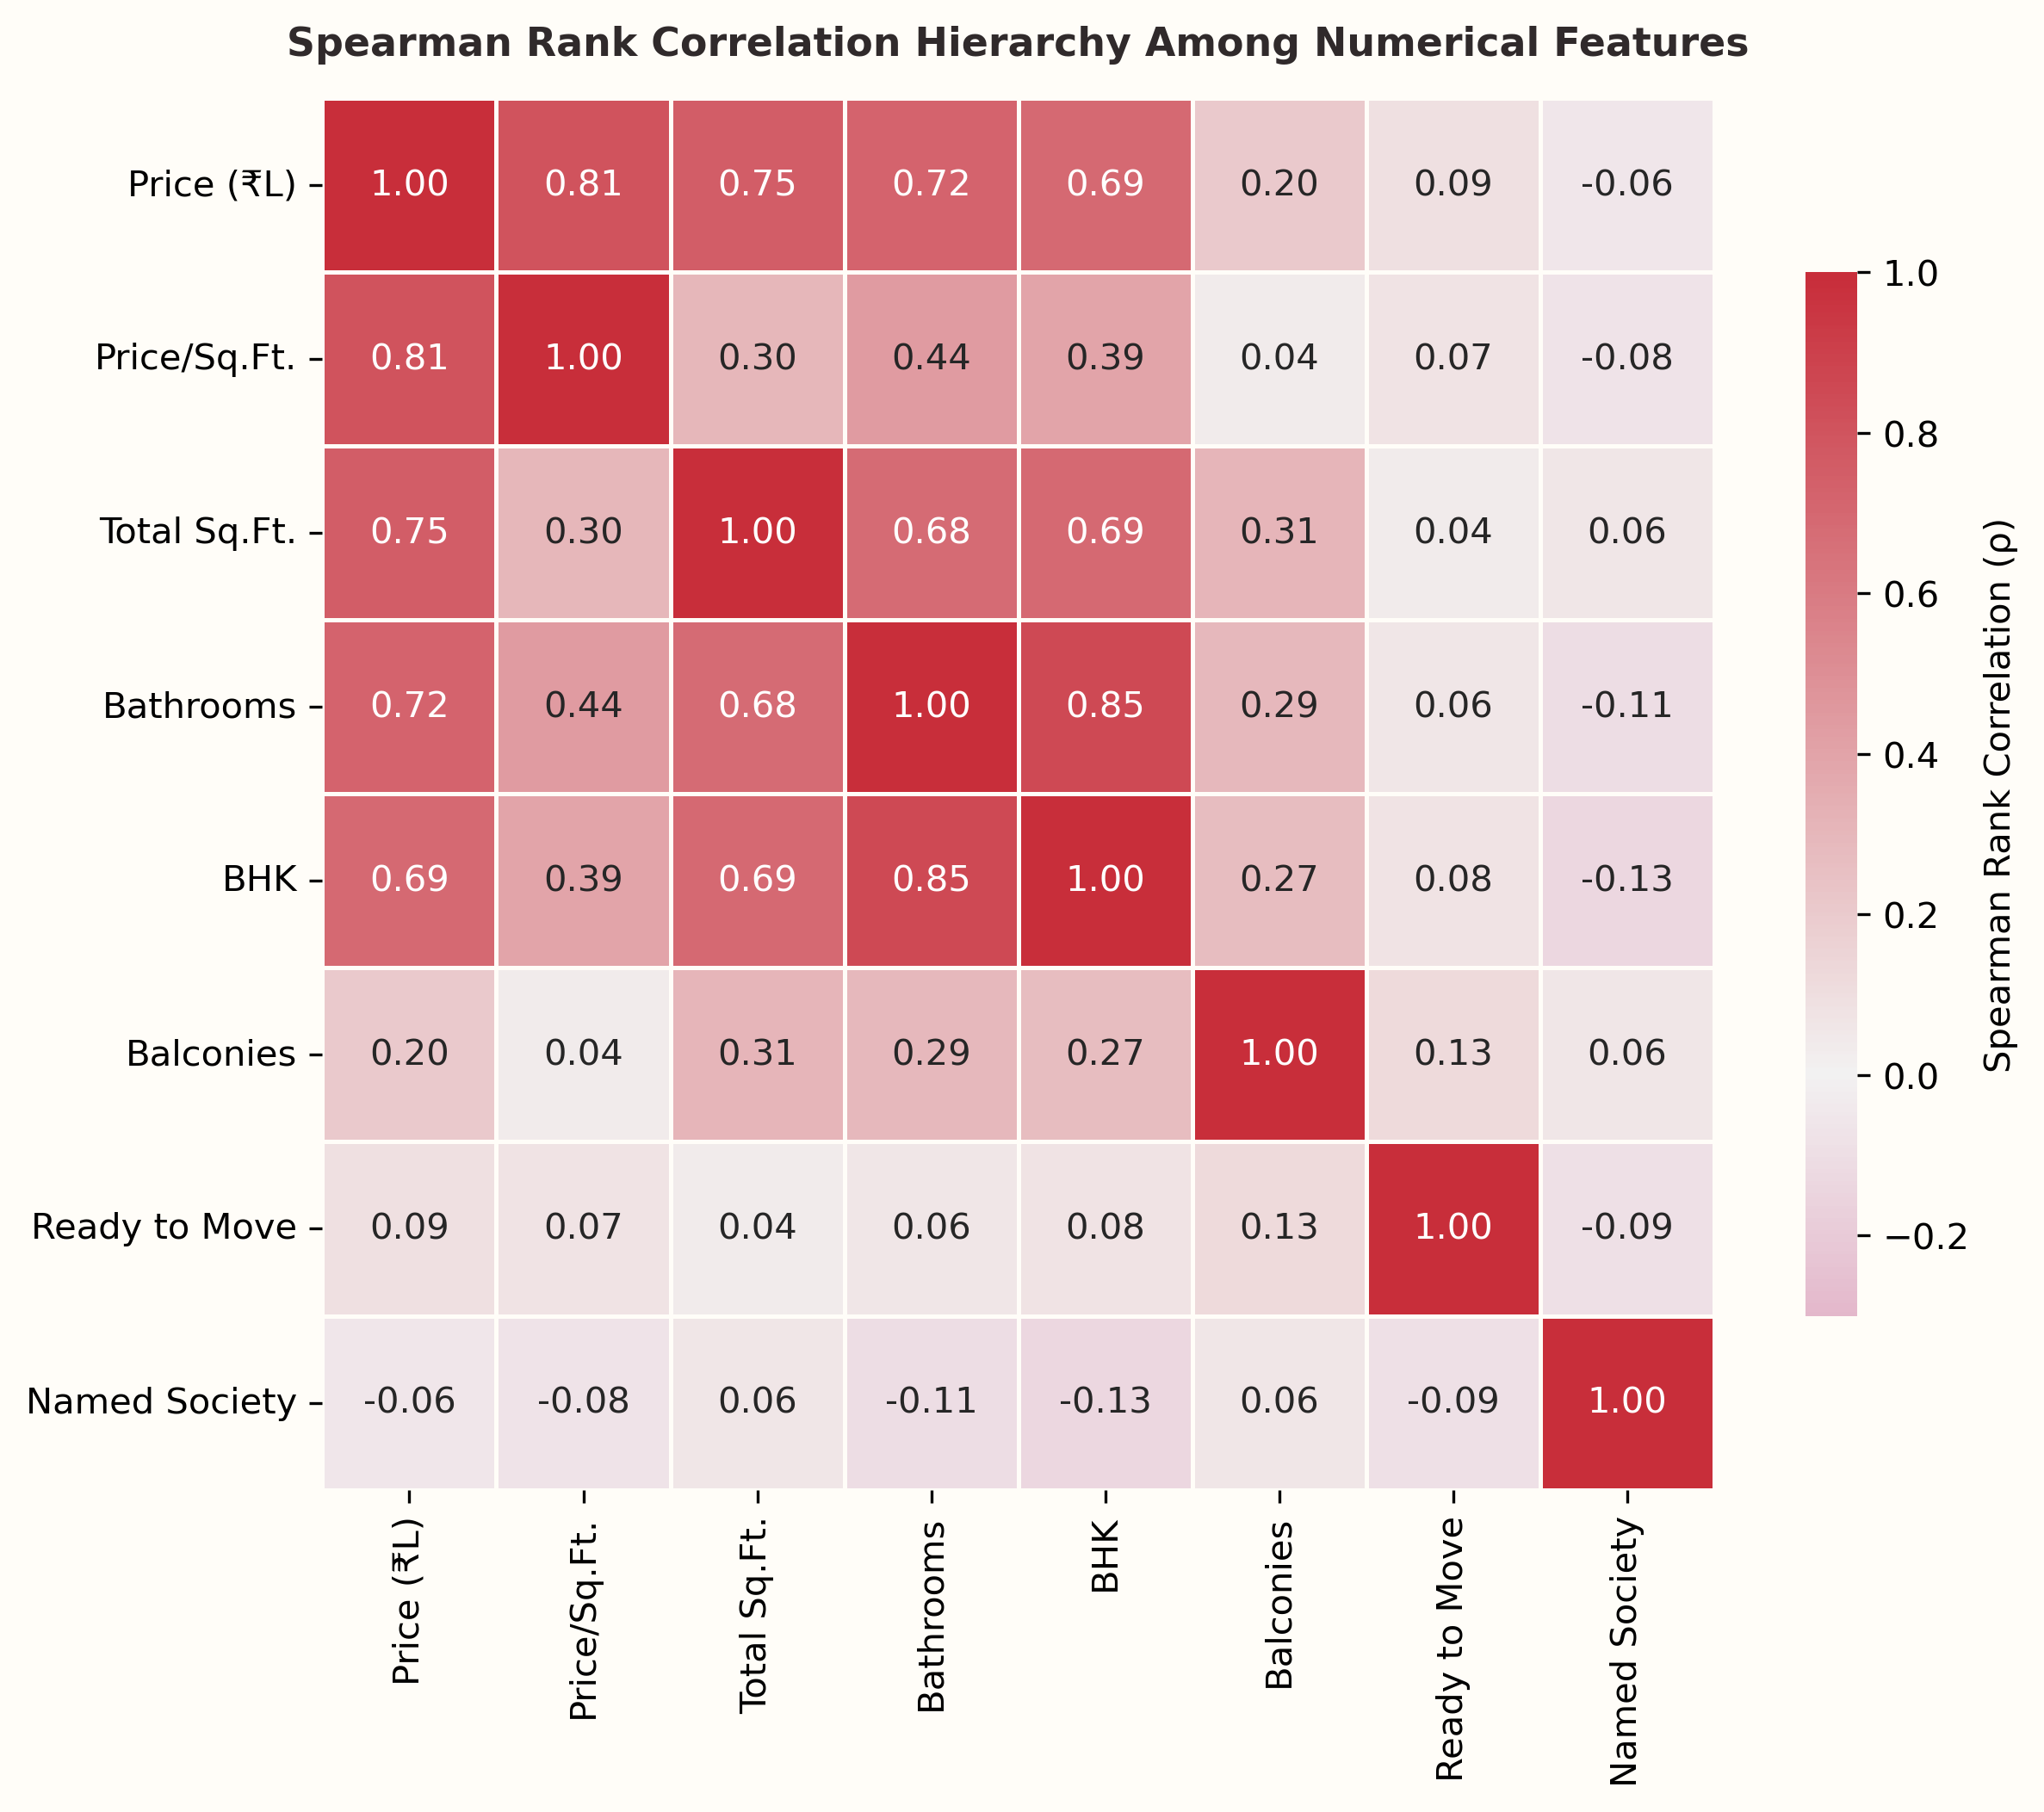

In [9]:
fig6_path = config.PROJECT_ROOT / "reports" / "figures" / "bengaluru" / "06_correlation_heatmap_numerical.png"
display(Image(filename=str(fig6_path)))


## 7. Data Quality Audit: Sensitivity Analysis of the 151 Excluded Anomaly Records

### Governance & Rationale for Exclusion
In Phase 2, exactly **151 severe physical anomaly records** were filtered:
1. **Area Typos (< 100 sq. ft., 7 records)**: Examples include 1 sq. ft. for a 4-bedroom villa priced at ₹120 Lakhs, and 5 sq. ft. for a 7-BHK home.
2. **Impossible Bedroom Packing (< 150 sq. ft./BHK, 144 records)**: Instances such as 8 bedrooms in 600 sq. ft. ($75\text{ sq. ft./BHK}$) or 43 bedrooms in 2,400 sq. ft. ($55.8\text{ sq. ft./BHK}$).

### Empirical Impact on Findings
As visualized below, if these 151 records were retained:
- The maximum price per square foot would explode to **₹12,000,000 / sq. ft. (₹1.2 Crore per sq. ft.)** due to dividing a ₹120 Lakh price by 1 sq. ft.!
- Mean price per sq. ft. would distort from **₹6,644** up to **₹122,900 / sq. ft.**, rendering unit rate analytics invalid.


,Metric,"Clean Dataset (n=12,640)",Excluded Anomalies (n=151)
0,Record Count,"12,640",626
1,Median Sqft,"1,293.0 sqft","1,317.5 sqft"
2,Median Sqft/BHK,555.0 sqft/bhk,551.5 sqft/bhk
3,Median Price (₹L),₹72.0L,₹75.0L
4,Median Price/Sqft,"₹5,445/sqft","₹5,500/sqft"
5,Max Price/Sqft,"₹176,471/sqft","₹50,350/sqft"


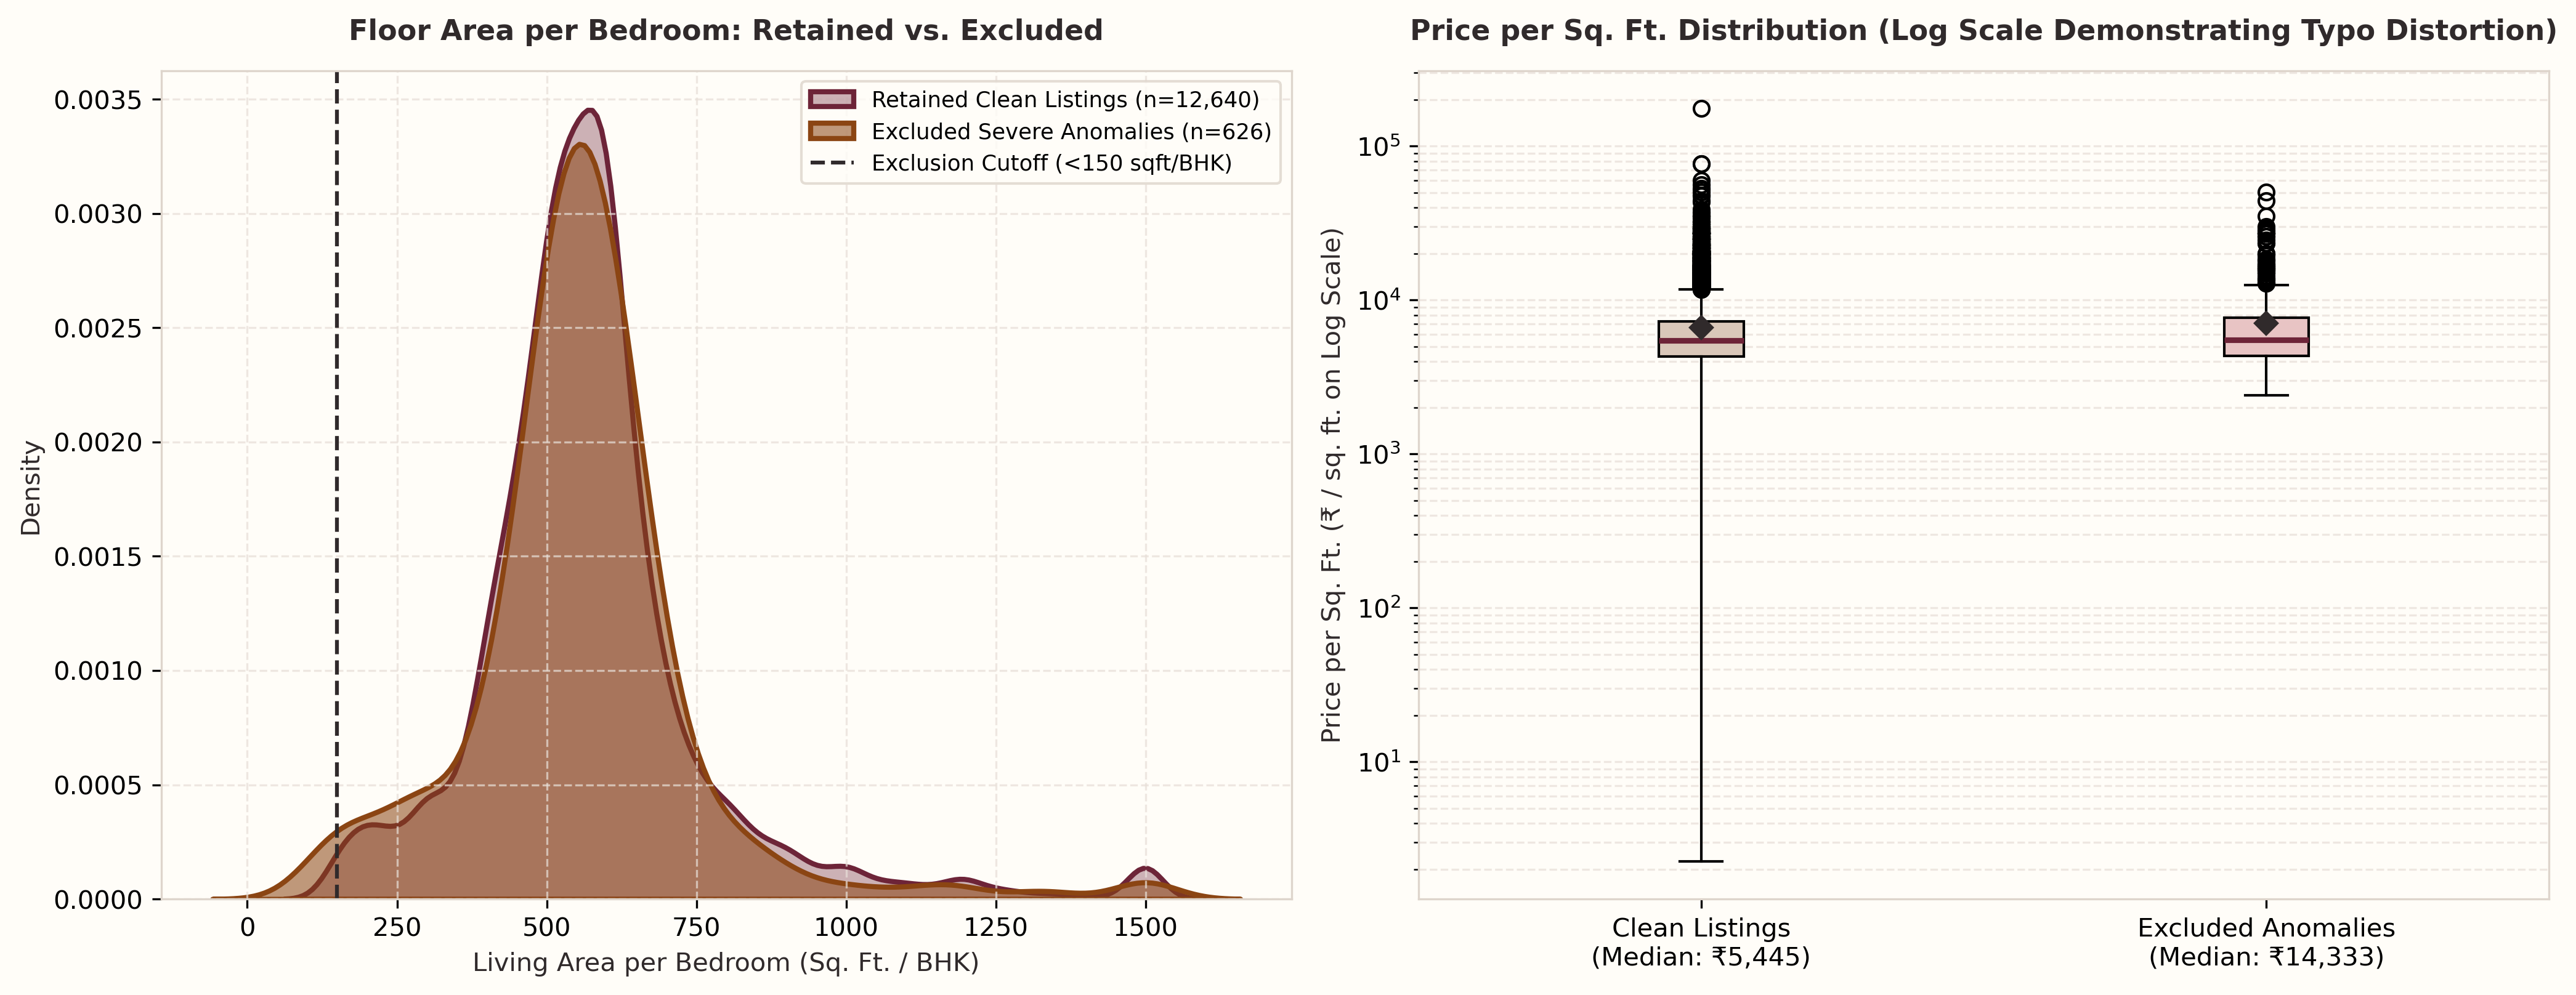

In [10]:
df_all, _ = clean_bengaluru_data(filter_severe_anomalies=False)
excluded = df_all[~df_all.index.isin(df.index)]

comp_table = pd.DataFrame({
    'Metric': ['Record Count', 'Median Sqft', 'Median Sqft/BHK', 'Median Price (₹L)', 'Median Price/Sqft', 'Max Price/Sqft'],
    'Clean Dataset (n=12,640)': [
        f"{len(df):,}",
        f"{df['total_sqft_clean'].median():,.1f} sqft",
        f"{df['sqft_per_bhk'].median():.1f} sqft/bhk",
        f"₹{df['price'].median():.1f}L",
        f"₹{df['price_per_sqft'].median():,.0f}/sqft",
        f"₹{df['price_per_sqft'].max():,.0f}/sqft"
    ],
    'Excluded Anomalies (n=151)': [
        f"{len(excluded):,}",
        f"{excluded['total_sqft_clean'].median():,.1f} sqft",
        f"{excluded['sqft_per_bhk'].median():.1f} sqft/bhk",
        f"₹{excluded['price'].median():.1f}L",
        f"₹{excluded['price_per_sqft'].median():,.0f}/sqft",
        f"₹{excluded['price_per_sqft'].max():,.0f}/sqft"
    ]
})
display(comp_table)

fig7_path = config.PROJECT_ROOT / "reports" / "figures" / "bengaluru" / "07_anomaly_exclusion_impact.png"
display(Image(filename=str(fig7_path)))


## 8. Summary of Findings & Modeling Recommendations

### Key Empirical Findings
1. **Heavy Right-Skewed Target**: The target price has positive skewness of **7.95**. Applying a `log1p` transformation normalizes skewness to **0.86**, confirming that training on log scale with `TransformedTargetRegressor` is mathematically appropriate.
2. **Land Premium Over Apartments**: Plot Area properties trade at more than double the median price of Super built-up apartments (₹145.0L vs ₹65.3L).
3. **High Spatial Disparity Across Localities**: Prime core localities (Malleshwaram, Rajaji Nagar, Frazer Town, Indira Nagar) trade at 3x–4x the median price of peripheral suburbs (e.g. Electronic City, Uttarahalli).
4. **Scale & Utility Predominance**: Living area (0.75), bathrooms (0.72), and bedroom count (0.69) are the most influential structural attributes.

### Modeling Recommendations & Safeguards
1. **Target Transformation**: Use `TransformedTargetRegressor(regressor, func=np.log1p, inverse_func=np.expm1)`.
2. **Categorical Handling for Localities**: `location_clean` contains ~240 consolidated micro-markets. Use `OneHotEncoder(handle_unknown='ignore')` to ensure unseen test localities default gracefully to the base intercept without crashing inference.
3. **Imputation Safeguards**: Use median imputation for missing `bhk` (16 rows), `bath` (73 rows), and `balcony` (568 rows) fitted strictly on training data.
4. **Attribution & Limitations**: Real estate portal asking prices reflect list quotes, not registered deed transaction prices. This distinction must be preserved across all project interfaces.
